# Do descriptors see the crossover region?

**Question.** Atom-centred ML descriptors get the long-range zero right by construction, and the equilibrium region is well sampled. The part in between, where bonds are partially broken and the wavefunction turns multireference, is what energized molecules explore. Which descriptor families actually carry information there, and which ones interpolate across it when the training data is thin?

**Plan**
1. Exact references: FCI/cc-pVDZ for H₂ dissociation and for the collinear H + H₂ ⇌ H₂ + H exchange (the smallest "bag of exchanging atoms").
2. A multireference diagnostic (effective unpaired electrons from FCI natural occupations) to *define* the crossover region instead of guessing it.
3. Three descriptor families, all two-body and permutation-invariant:
   - **SOAP-like radial**: Gaussians on a grid × smooth cosine cutoff (the standard MLIP choice).
   - **Morse / reduced-distance**: exp(−α(r/r₀ − 1)) for several α; no cutoff, decays naturally.
   - **Overlap**: analytic Slater 1s overlaps S(ζr) for several ζ, and S². Exchange-like decay by construction.
4. Two tests: descriptor *sensitivity* (‖dX/dr‖ where dE/dr ≠ 0) and *gap interpolation* (train on equilibrium + dissociated geometries only, predict the crossover).

Everything is cheap: the whole notebook runs in a minute or two on a laptop. Swap in your own molecule/method in the `reference_*` functions.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pyscf import gto, scf, fci

KCAL = 627.5095          # hartree -> kcal/mol
BOHR = 0.529177          # angstrom per bohr
BASIS = 'cc-pvdz'

# palette: fixed categorical order
C_SOAP, C_MORSE, C_OVLP, C_REF = '#2a78d6', '#eb6834', '#1baf7a', '#3d3d3a'
C_SHADE = '#eda100'
DIVERGE = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#e9e8e4', '#eb6834'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'lines.linewidth': 2, 'font.size': 10, 'legend.frameon': False})

## 1 · Exact reference for H₂ and a crossover diagnostic

FCI is exact within the basis, so any failure later is the descriptor's, not the reference's. RHF and broken-symmetry UHF are shown to make the multireference point concrete.

**Effective unpaired electrons** n_u = Σᵢ min(nᵢ, 2 − nᵢ) over FCI natural occupations: 0 for a closed-shell bond, 2 for two separated radicals. The *crossover* is where 0.1 < n_u < 1.9.

In [3]:
def h_atom_energy():
    mol = gto.M(atom='H 0 0 0', basis=BASIS, spin=1, verbose=0)
    return scf.UHF(mol).run().e_tot          # exact within basis for 1 electron

E_H = h_atom_energy()

def fci_with_diagnostic(mol, mf):
    cis = fci.FCI(mf)
    e, civec = cis.kernel()
    norb = mf.mo_coeff.shape[1]
    rdm1 = cis.make_rdm1(civec, norb, mol.nelec)
    occ = np.linalg.eigvalsh(rdm1)
    return e, np.sum(np.minimum(occ, 2 - occ))

def broken_symmetry_uhf(mol, rhf):
    # rotate HOMO/LUMO in opposite directions for alpha and beta to break spin symmetry
    nocc = mol.nelectron // 2
    c = rhf.mo_coeff
    h, l = c[:, nocc - 1], c[:, nocc]
    ca, cb = c.copy(), c.copy()
    ca[:, nocc - 1] = (h + l) / np.sqrt(2)
    cb[:, nocc - 1] = (h - l) / np.sqrt(2)
    occ = np.zeros(c.shape[1]); occ[:nocc] = 1
    dm = np.array([ca @ np.diag(occ) @ ca.T, cb @ np.diag(occ) @ cb.T])
    return scf.UHF(mol).run(dm)

def reference_h2(r):
    mol = gto.M(atom=f'H 0 0 0; H 0 0 {r}', basis=BASIS, verbose=0)
    rhf = scf.RHF(mol).run()
    uhf = broken_symmetry_uhf(mol, rhf)
    e_fci, nu = fci_with_diagnostic(mol, rhf)
    return rhf.e_tot, uhf.e_tot, e_fci, nu

r_h2 = np.linspace(0.45, 6.0, 120)
ref = np.array([reference_h2(r) for r in r_h2])
E_rhf, E_uhf, E_fci, NU = [(ref[:, k] - 2 * E_H) * (KCAL if k < 3 else 1) for k in range(3)] + [ref[:, 3]]
NU = ref[:, 3]

cross = (NU > 0.1) & (NU < 1.9)
r_lo, r_hi = r_h2[cross].min(), r_h2[cross].max()
print(f'FCI De = {-E_fci.min():.1f} kcal/mol at r = {r_h2[E_fci.argmin()]:.2f} Å')
print(f'crossover region (0.1 < n_u < 1.9): {r_lo:.2f}–{r_hi:.2f} Å')

FCI De = 103.5 kcal/mol at r = 0.78 Å
crossover region (0.1 < n_u < 1.9): 0.96–3.71 Å


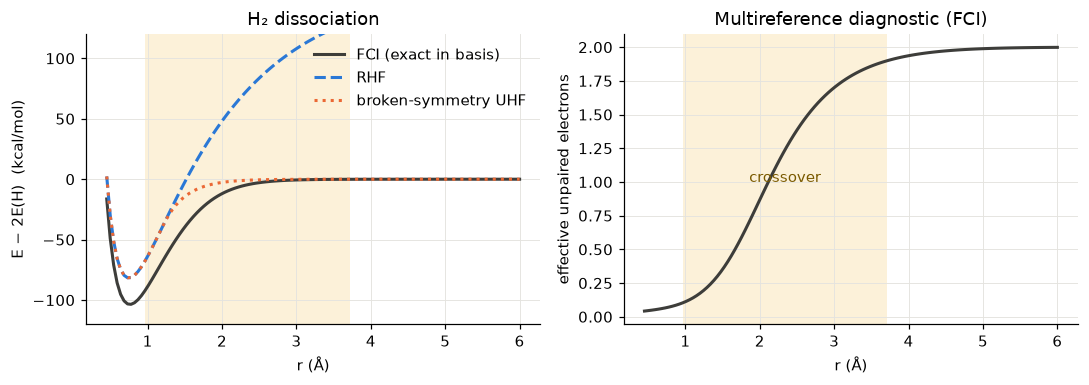

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
for ax in (a1, a2):
    ax.axvspan(r_lo, r_hi, color=C_SHADE, alpha=0.15, lw=0)
a1.plot(r_h2, E_fci, color=C_REF, label='FCI (exact in basis)')
a1.plot(r_h2, E_rhf, color=C_SOAP, ls='--', label='RHF')
a1.plot(r_h2, E_uhf, color=C_MORSE, ls=':', label='broken-symmetry UHF')
a1.set(xlabel='r (Å)', ylabel='E − 2E(H)  (kcal/mol)', ylim=(-120, 120), title='H₂ dissociation')
a1.legend(loc='upper right')
a2.plot(r_h2, NU, color=C_REF)
a2.set(xlabel='r (Å)', ylabel='effective unpaired electrons', title='Multireference diagnostic (FCI)')
a2.text((r_lo + r_hi) / 2, 1.0, 'crossover', ha='center', color='#7a5a00')
plt.tight_layout(); plt.savefig('fig1_h2_reference.png', bbox_inches='tight'); plt.show()

## 2 · Three descriptor families

All are functions of interatomic distance only, summed over neighbours per atom, which makes them permutation invariant and graph-free (no bond topology needed when atoms swap partners).

In [5]:
def cos_cutoff(r, rc):
    return np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

def soap_radial(r, rc=5.0, n=16):
    # Gaussian radial basis x smooth cutoff (SOAP/ACE/Behler-style radial channel)
    mu = np.linspace(0.5, rc, n)
    sig = mu[1] - mu[0]
    r = np.atleast_1d(r)[:, None]
    return np.exp(-(r - mu) ** 2 / (2 * sig ** 2)) * cos_cutoff(r, rc)

def morse_basis(r, r0=0.74, alphas=np.geomspace(0.4, 5.0, 10)):
    # reduced distance (r0 = sum of covalent radii), no cutoff; -> 0 at infinity
    r = np.atleast_1d(r)[:, None]
    return np.exp(-alphas * (r / r0 - 1.0))

def overlap_basis(r, zetas=np.array([0.6, 0.8, 1.0, 1.24, 1.5])):
    # analytic Slater 1s-1s overlap S = e^{-p}(1 + p + p^2/3), p = zeta*r/a0; plus S^2 (exchange-like)
    p = np.atleast_1d(r)[:, None] * zetas / BOHR
    S = np.exp(-p) * (1 + p + p ** 2 / 3)
    return np.hstack([S, S ** 2])

DESCRIPTORS = {'SOAP-like radial (rc = 5 Å)': (soap_radial, C_SOAP),
               'Morse / reduced distance': (morse_basis, C_MORSE),
               'Slater overlap S, S²': (overlap_basis, C_OVLP)}

def atomic_envs(positions, phi):
    # per-atom descriptor G_i = sum_j phi(r_ij)
    d = np.linalg.norm(positions[:, None] - positions[None], axis=-1)
    n = len(positions)
    return np.array([sum(phi(d[i, j])[0] for j in range(n) if j != i) for i in range(n)])

### Sensitivity: does the descriptor move where the energy moves?

If ‖dX/dr‖ (features standardised) collapses in a region where |dE/dr| is still large, the model is blind there: geometries with different energies look nearly identical.

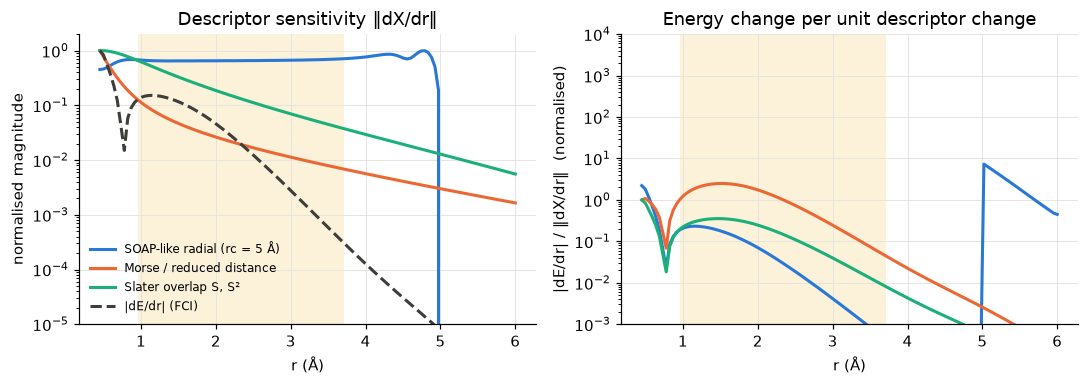

In [6]:
def sensitivity(phi, r, h=1e-4):
    X = phi(r)
    scale = X.std(axis=0) + 1e-12
    dX = (phi(r + h) - phi(r - h)) / (2 * h) / scale
    return np.linalg.norm(dX, axis=1)

dE = np.abs(np.gradient(E_fci, r_h2))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
for ax in (a1, a2):
    ax.axvspan(r_lo, r_hi, color=C_SHADE, alpha=0.15, lw=0)
for name, (phi, col) in DESCRIPTORS.items():
    s = sensitivity(phi, r_h2)
    a1.semilogy(r_h2, s / s.max(), color=col, label=name)
    a2.plot(r_h2, (dE / dE.max()) / np.maximum(s / s.max(), 1e-6), color=col, label=name)
a1.semilogy(r_h2, dE / dE.max(), color=C_REF, ls='--', label='|dE/dr| (FCI)')
a1.set(xlabel='r (Å)', ylabel='normalised magnitude', ylim=(1e-5, 2), title='Descriptor sensitivity ‖dX/dr‖')
a1.legend(fontsize=8, loc='lower left')
a2.set(xlabel='r (Å)', ylabel='|dE/dr| / ‖dX/dr‖  (normalised)', yscale='log',
       title='Energy change per unit descriptor change')
a2.set_ylim(1e-3, 1e4)
plt.tight_layout(); plt.savefig('fig2_sensitivity.png', bbox_inches='tight'); plt.show()

**Reading this.** The SOAP-like basis is *not* blind: its sensitivity is high everywhere inside the cutoff. Its weakness shows up in the next test instead. The Morse and overlap bases lose sensitivity exponentially, at roughly the rate the energy gradient itself decays, so the energy-per-descriptor ratio (right) stays bounded through the crossover rather than spiking. (The SOAP ratio jumps past 5 Å only because the features are identically zero beyond the cutoff.)

## 3 · Gap-interpolation test on H₂

Training data mimics a typical dataset: equilibrium-ish MD (0.5–1.2 Å) plus separated fragments (≥ 3.5 Å), **nothing in between**. Model: kernel ridge regression with a structure kernel K(A,B) = Σᵢⱼ k(Gᵢᴬ, Gⱼᴮ), i.e. an atomic energy decomposition as in GAP / Behler–Parrinello. Hyperparameters by cross-validation on the training set only.

In [7]:
def structure_kernel(GA, GB, gamma):
    # GA, GB: lists of (n_atoms, n_feat) arrays; sum of RBF over atom pairs
    K = np.zeros((len(GA), len(GB)))
    for a, ga in enumerate(GA):
        for b, gb in enumerate(GB):
            d2 = ((ga[:, None] - gb[None]) ** 2).sum(-1)
            K[a, b] = np.exp(-gamma * d2).sum()
    return K

class SumKernelKRR:
    def __init__(self, gammas=np.geomspace(1e-3, 3, 10), lams=np.geomspace(1e-8, 1e-1, 8), k=5, seed=0):
        self.gammas, self.lams, self.k, self.seed = gammas, lams, k, seed
    def _fit(self, G, y, gamma, lam):
        K = structure_kernel(G, G, gamma)
        return np.linalg.solve(K + lam * np.eye(len(G)), y - self.mu)
    def fit(self, G, y):
        allf = np.vstack(G); self.m, self.s = allf.mean(0), allf.std(0) + 1e-12
        G = [(g - self.m) / self.s for g in G]
        self.mu = y.mean()
        idx = np.random.default_rng(self.seed).permutation(len(G)); folds = np.array_split(idx, self.k)
        best = (np.inf, None)
        for gm in self.gammas:
            for lam in self.lams:
                err = []
                for f in folds:
                    tr = np.setdiff1d(idx, f)
                    w = self._fit([G[i] for i in tr], y[tr], gm, lam)
                    p = structure_kernel([G[i] for i in f], [G[i] for i in tr], gm) @ w + self.mu
                    err.append(((p - y[f]) ** 2).mean())
                if np.mean(err) < best[0]:
                    best = (np.mean(err), (gm, lam))
        self.gamma, self.lam = best[1]
        self.G = G; self.w = self._fit(G, y, self.gamma, self.lam)
        return self
    def predict(self, G):
        G = [(g - self.m) / self.s for g in G]
        return structure_kernel(G, self.G, self.gamma) @ self.w + self.mu

pos_h2 = [np.array([[0, 0, 0], [0, 0, r]]) for r in r_h2]
train = ((r_h2 >= 0.5) & (r_h2 <= 1.2)) | (r_h2 >= 3.5)
train_idx = np.where(train)[0][::2]                     # thin it out a little
print(f'{len(train_idx)} training geometries, none in {r_lo:.2f}–{r_hi:.2f} Å except edges')

pred_h2, rmse_h2 = {}, {}
for name, (phi, col) in DESCRIPTORS.items():
    G = [atomic_envs(p, phi) for p in pos_h2]
    model = SumKernelKRR().fit([G[i] for i in train_idx], E_fci[train_idx])
    pred_h2[name] = model.predict(G)
    rmse_h2[name] = np.sqrt(np.mean((pred_h2[name][cross] - E_fci[cross]) ** 2))
    print(f'{name:30s} crossover RMSE = {rmse_h2[name]:6.2f} kcal/mol')

35 training geometries, none in 0.96–3.71 Å except edges
SOAP-like radial (rc = 5 Å)    crossover RMSE =  15.52 kcal/mol
Morse / reduced distance       crossover RMSE =   1.32 kcal/mol
Slater overlap S, S²           crossover RMSE =   1.13 kcal/mol


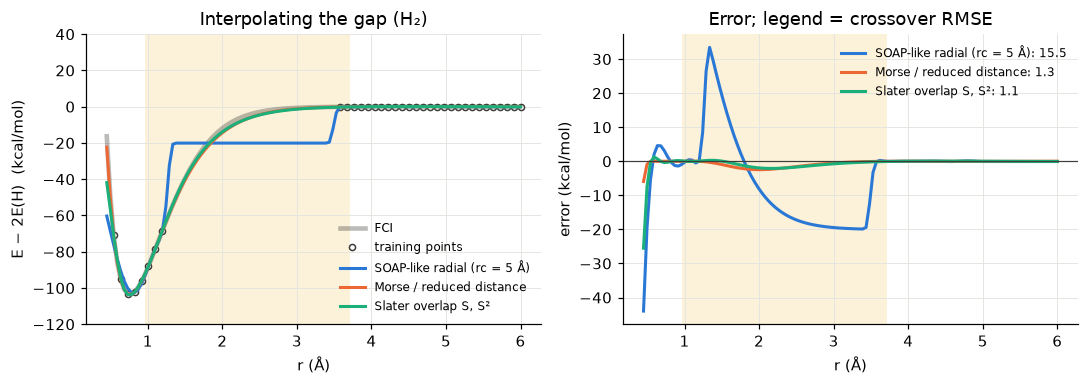

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
for ax in (a1, a2):
    ax.axvspan(r_lo, r_hi, color=C_SHADE, alpha=0.15, lw=0)
a1.plot(r_h2, E_fci, color=C_REF, lw=3, alpha=0.35, label='FCI')
a1.plot(r_h2[train_idx], E_fci[train_idx], 'o', ms=4, mfc='white', mec=C_REF, label='training points')
for name, (phi, col) in DESCRIPTORS.items():
    a1.plot(r_h2, pred_h2[name], color=col, label=name)
    a2.plot(r_h2, pred_h2[name] - E_fci, color=col, label=f'{name}: {rmse_h2[name]:.1f}')
a1.set(xlabel='r (Å)', ylabel='E − 2E(H)  (kcal/mol)', ylim=(-120, 40), title='Interpolating the gap (H₂)')
a1.legend(fontsize=8, loc='lower right')
a2.axhline(0, color=C_REF, lw=0.8)
a2.set(xlabel='r (Å)', ylabel='error (kcal/mol)', title='Error; legend = crossover RMSE')
a2.legend(fontsize=8)
plt.tight_layout(); plt.savefig('fig3_h2_gap.png', bbox_inches='tight'); plt.show()

Is the SOAP failure just narrow Gaussians? Sweep the radial basis width at fixed cutoff.

In [9]:
for n in [16, 8, 5, 3]:
    phi = lambda r, n=n: soap_radial(r, rc=5.0, n=n)
    G = [atomic_envs(p, phi) for p in pos_h2]
    m = SumKernelKRR().fit([G[i] for i in train_idx], E_fci[train_idx])
    p = m.predict(G)
    print(f'{n:2d} Gaussians (width {4.5 / (n - 1):.2f} Å): crossover RMSE = {np.sqrt(np.mean((p[cross] - E_fci[cross]) ** 2)):7.2f} kcal/mol')

16 Gaussians (width 0.30 Å): crossover RMSE =   15.52 kcal/mol
 8 Gaussians (width 0.64 Å): crossover RMSE =   14.08 kcal/mol
 5 Gaussians (width 1.12 Å): crossover RMSE =  176.17 kcal/mol
 3 Gaussians (width 2.25 Å): crossover RMSE =  118.84 kcal/mol


## 4 · Collinear H + H₂ exchange: atoms swapping partners

Hₐ–H_b–H_c on a grid of (r₁ = r_ab, r₂ = r_bc). The transition state sits on the symmetric stretch where both bonds are half-formed, the case where "which atom is bonded to which" has no answer. FCI doublet in cc-pVDZ; FCI in the full orbital space is invariant to the starting orbitals, so ROHF convergence quality doesn't matter.

In [10]:
def reference_h3(r1, r2):
    mol = gto.M(atom=f'H 0 0 0; H 0 0 {r1}; H 0 0 {r1 + r2}', basis=BASIS, spin=1, verbose=0)
    mf = scf.ROHF(mol); mf.max_cycle = 80; mf.run()
    e, _ = fci.FCI(mf).kernel()
    return e

g = np.linspace(0.5, 3.5, 26)
R1, R2 = np.meshgrid(g, g, indexing='ij')
E3 = np.array([[reference_h3(a, b) for b in g] for a in g])
E3 = (E3 - 3 * E_H) * KCAL                                   # relative to three free H atoms
E_H2min = E_fci.min()
sym = np.diag(E3)
print(f'symmetric-stretch saddle ≈ {sym.min() - E_H2min:.1f} kcal/mol above H + H2 at r = {g[sym.argmin()]:.2f} Å (grid estimate)')

symmetric-stretch saddle ≈ 10.6 kcal/mol above H + H2 at r = 0.98 Å (grid estimate)


In [11]:
pos_h3 = [np.array([[0, 0, 0], [0, 0, a], [0, 0, a + b]]) for a, b in zip(R1.ravel(), R2.ravel())]
y3 = E3.ravel()
rmin, rmax = np.minimum(R1, R2).ravel(), np.maximum(R1, R2).ravel()

# 'typical dataset': one intact bond near equilibrium with the third atom anywhere,
# plus everything dissociated. Excluded: both bonds partially formed.
bag = (rmin > 0.85) & (rmax < 2.0)                         # the in-between "bag" region
train3 = ((rmin < 0.95) | (rmin > 2.2)) & ~bag
rng = np.random.default_rng(1)
tr3 = rng.choice(np.where(train3)[0], size=120, replace=False)
print(f'{len(tr3)} training geometries; {bag.sum()} test points in the bag region')

pred3, rmse3 = {}, {}
for name, (phi, col) in DESCRIPTORS.items():
    G = [atomic_envs(p, phi) for p in pos_h3]
    m = SumKernelKRR().fit([G[i] for i in tr3], y3[tr3])
    pred3[name] = m.predict(G).reshape(E3.shape)
    rmse3[name] = np.sqrt(np.mean((pred3[name].ravel()[bag] - y3[bag]) ** 2))
    print(f'{name:30s} bag-region RMSE = {rmse3[name]:6.2f} kcal/mol')

120 training geometries; 100 test points in the bag region
SOAP-like radial (rc = 5 Å)    bag-region RMSE =  86.88 kcal/mol
Morse / reduced distance       bag-region RMSE =   2.92 kcal/mol
Slater overlap S, S²           bag-region RMSE =   6.25 kcal/mol


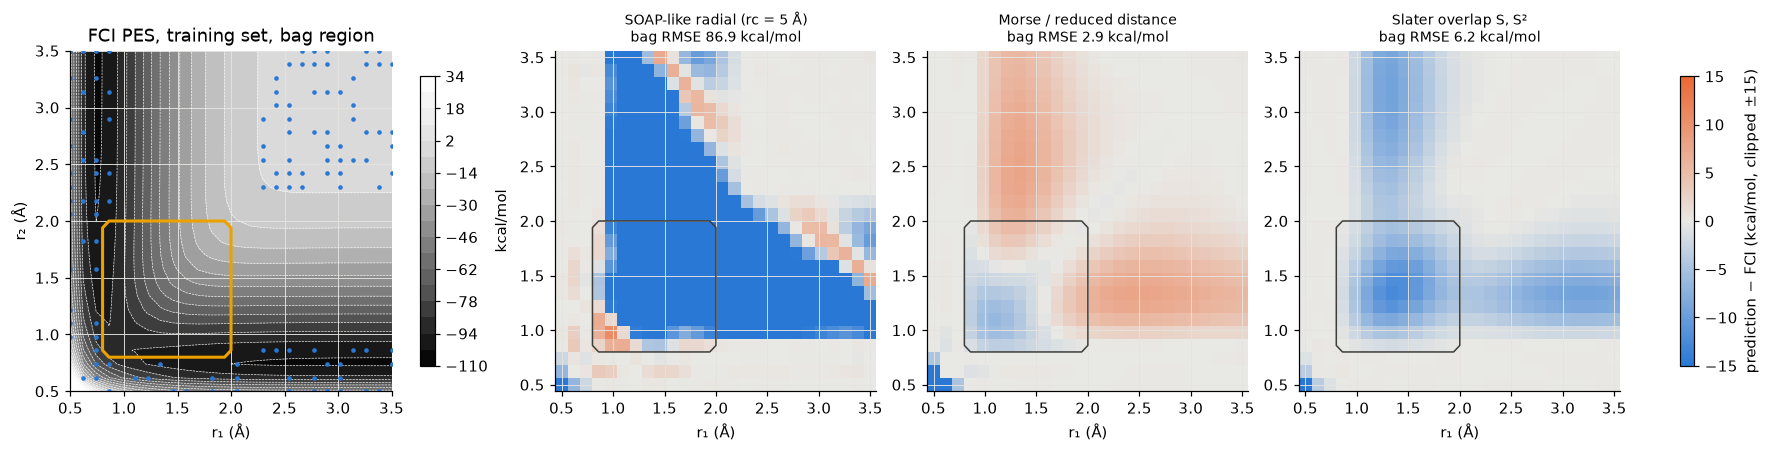

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.0), layout='constrained')
lv = np.arange(-110, 40, 8)
cs = axes[0].contourf(R1, R2, np.clip(E3, -110, 40), levels=lv, cmap='Greys_r')
axes[0].contour(R1, R2, E3, levels=lv, colors='white', linewidths=0.4)
axes[0].plot(R1.ravel()[tr3], R2.ravel()[tr3], '.', color=C_SOAP, ms=4, label='training')
axes[0].contour(R1, R2, bag.reshape(E3.shape).astype(float), levels=[0.5], colors=C_SHADE, linewidths=2)
axes[0].set(title='FCI PES, training set, bag region', xlabel='r₁ (Å)', ylabel='r₂ (Å)')
plt.colorbar(cs, ax=axes[0], label='kcal/mol', shrink=0.85)
lim = 15
for ax, (name, (phi, col)) in zip(axes[1:], DESCRIPTORS.items()):
    im = ax.pcolormesh(R1, R2, np.clip(pred3[name] - E3, -lim, lim), cmap=DIVERGE, vmin=-lim, vmax=lim, shading='auto')
    ax.contour(R1, R2, bag.reshape(E3.shape).astype(float), levels=[0.5], colors=C_REF, linewidths=1)
    ax.set(title=f'{name}\nbag RMSE {rmse3[name]:.1f} kcal/mol', xlabel='r₁ (Å)')
    ax.title.set_fontsize(9)
plt.colorbar(im, ax=axes[1:], label='prediction − FCI (kcal/mol, clipped ±15)', shrink=0.85)
plt.savefig('fig4_h3_bag.png', bbox_inches='tight'); plt.show()

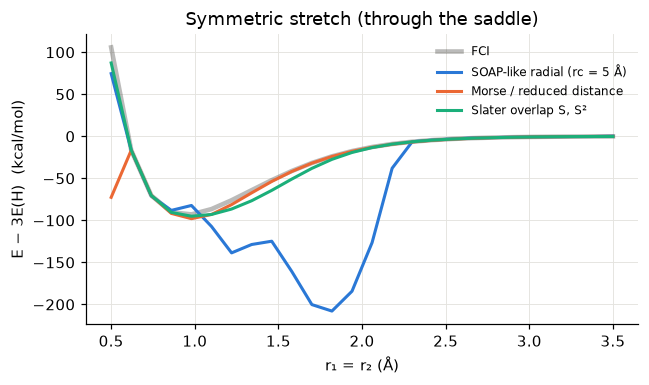

                               saddle barrier vs H + H2 (kcal/mol)
FCI                               10.6
SOAP-like radial (rc = 5 Å)     -104.4
Morse / reduced distance           5.5
Slater overlap S, S²               8.4


In [13]:
# symmetric stretch: the line through the saddle where neither bond 'owns' the middle atom
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(g, np.diag(E3), color=C_REF, lw=3, alpha=0.35, label='FCI')
for name, (phi, col) in DESCRIPTORS.items():
    ax.plot(g, np.diag(pred3[name]), color=col, label=name)
ax.set(xlabel='r₁ = r₂ (Å)', ylabel='E − 3E(H)  (kcal/mol)', title='Symmetric stretch (through the saddle)')
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('fig5_h3_symmetric.png', bbox_inches='tight'); plt.show()

print(f'{"":30s} saddle barrier vs H + H2 (kcal/mol)')
print(f'{"FCI":30s} {np.diag(E3).min() - E_H2min:7.1f}')
for name in DESCRIPTORS:
    print(f'{name:30s} {np.diag(pred3[name]).min() - E_H2min:7.1f}')

## 5 · Takeaways

Numbers are from this run (FCI/cc-pVDZ references; crossover/bag regions deliberately left out of training).

| Descriptor | H₂ crossover RMSE | H₃ bag RMSE | H₃ saddle (FCI 10.6) |
|---|---|---|---|
| SOAP-like radial, rc = 5 Å | 15.5 | 86.9 | −104 (phantom well) |
| Morse / reduced distance | 1.3 | 2.9 | 5.5 |
| Slater overlap S, S² | 1.1 | 6.3 | 8.4 |

All values in kcal/mol.

1. **The long-range zero is not the hard part.** All three get it, either by cutoff or by natural decay.
2. **Localised radial bases make the crossover an extrapolation.** SOAP-style Gaussian channels are sensitive everywhere, but a half-broken bond lights up channels that equilibrium and dissociated data never touched. The kernel has nothing to compare against, so predictions fall back to the training mean or worse; on H₃ that produces a spurious well ~100 kcal/mol deep at the saddle. Changing the Gaussian width didn't fix it. For this family of MLIPs, crossover *data* is the whole game.
3. **Monotone, globally decaying bases make it an interpolation.** In Morse and overlap features the stretched bond lies *between* bonded and separated in feature space, so sparse data at both ends constrains it. Their sensitivity also decays at about the rate the energy gradient does, which is the physical alignment you'd want.
4. **Two-body features run out at the saddle.** The remaining H₃ errors sit where both bonds are partly formed or one bond is stretched with a third atom nearby. A radial sum can't express that bond order is shared (the LEPS/bond-order-conservation physics), so the barrier comes out too low.

### Next steps worth trying
- **Overlap-built diabatic model:** a 2×2 (or 3×3) valence-bond Hamiltonian whose diagonals are H₂ + H in each arrangement and whose couplings are learned functions of the overlap features. The saddle and the correct asymptotes then come from the eigenvalue, not from fitting.
- **Three-body terms** (angular or product-of-overlap features) in the same monotone style.
- **Hybrid basis:** keep SOAP-like channels for short-range detail, add the overlap channels to carry the crossover; test whether that keeps the 1 kcal/mol interpolation while improving the equilibrium region.
- **Swap in a real target:** replace `reference_h2`/`reference_h3` with CASSCF/NEVPT2 scans of a bond in one of your energized molecules and rerun the same gap test.
- **Active learning check:** how many crossover points does SOAP need before it matches the overlap basis? That number is a useful cost estimate for sampling.